## 0. Mount google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Imports and configuration

In [ ]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Update this path to your project directory
PROJECT_ROOT = Path("/content/drive/MyDrive/AAI-521/project")

DATASET_DIR = PROJECT_ROOT / "datasets" / "camvid"
IMAGE_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "masks"

DATASET_OUTPUT_DIR = DATASET_DIR / "outputs"
LABELS_CSV = DATASET_OUTPUT_DIR / "image_labels.csv"
CLASS_DISTRIBUTION_CSV = DATASET_OUTPUT_DIR / "image_class_distribution.csv"

# Classification preprocessing configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Image directory exists:", IMAGE_DIR.exists())
print("Mask directory exists:", MASK_DIR.exists())
print("Labels CSV exists:", LABELS_CSV.exists())

Device: cuda
Image directory exists: True
Mask directory exists: True
Labels CSV exists: True


## 2. Load the labels generated in Notebook 01

In [ ]:
df = pd.read_csv(LABELS_CSV)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (701, 35)

Columns:
['image', 'filename', 'mask', 'Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall', 'number_of_classes']


,image,filename,mask,Animal,Archway,Bicyclist,Bridge,Building,Car,CartLuggagePram,...,SUVPickupTruck,TrafficCone,TrafficLight,Train,Tree,Truck_Bus,Tunnel,VegetationMisc,Wall,number_of_classes
0,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006690,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,0,...,1,0,1,0,1,1,0,0,0,14
1,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006720,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,1,0,1,0,1,1,0,0,0,15
2,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006750,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,1,0,1,0,1,1,0,0,0,15
3,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006780,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,1,0,1,0,1,1,0,0,0,15
4,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006810,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,1,...,1,0,1,0,1,1,0,0,0,18


In [ ]:
METADATA_COLUMNS = [
    "image",
    "filename",
    "mask",
    "number_of_classes"
]

CLASS_COLUMNS = [
    col for col in df.columns
    if col not in METADATA_COLUMNS
]

print("Number of source classes:", len(CLASS_COLUMNS))
print("Source classes:", CLASS_COLUMNS)

Number of source classes: 31
Source classes: ['Animal', 'Archway', 'Bicyclist', 'Bridge', 'Building', 'Car', 'CartLuggagePram', 'Child', 'Column_Pole', 'Fence', 'LaneMkgsDriv', 'LaneMkgsNonDriv', 'Misc_Text', 'MotorcycleScooter', 'OtherMoving', 'ParkingBlock', 'Pedestrian', 'Road', 'RoadShoulder', 'Sidewalk', 'SignSymbol', 'Sky', 'SUVPickupTruck', 'TrafficCone', 'TrafficLight', 'Train', 'Tree', 'Truck_Bus', 'Tunnel', 'VegetationMisc', 'Wall']


## 3. Validate the dataset records

In [ ]:
print("Missing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("Duplicate filenames:", df["filename"].duplicated().sum())
print("Duplicate image paths:", df["image"].duplicated().sum())

# Validate that class labels are binary
invalid_label_values = {}

for col in CLASS_COLUMNS:
    values = set(df[col].dropna().unique())
    if not values.issubset({0, 1}):
        invalid_label_values[col] = values

print("Columns with non-binary values:", invalid_label_values)

# Validate the number_of_classes column
calculated_class_count = df[CLASS_COLUMNS].sum(axis=1)

print(
    "Rows where number_of_classes does not match label count:",
    (calculated_class_count != df["number_of_classes"]).sum()
)

Missing values:


,0


Duplicate filenames: 0
Duplicate image paths: 0
Columns with non-binary values: {}
Rows where number_of_classes does not match label count: 0


## 4. Identify active and zero-frequency classes

In [ ]:
class_counts = df[CLASS_COLUMNS].sum().sort_values(ascending=False)

ACTIVE_CLASSES = class_counts[class_counts > 0].index.tolist()
ZERO_FREQUENCY_CLASSES = class_counts[class_counts == 0].index.tolist()

print("Total source classes:", len(CLASS_COLUMNS))
print("Active classes:", len(ACTIVE_CLASSES))
print("Zero-frequency classes:", len(ZERO_FREQUENCY_CLASSES))

print("\nZero-frequency classes:")
print(ZERO_FREQUENCY_CLASSES)

class_distribution = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage": (class_counts / len(df)) * 100
})

display(class_distribution)

Total source classes: 31
Active classes: 29
Zero-frequency classes: 2

Zero-frequency classes:
['Train', 'Tunnel']


,Image Count,Percentage
Road,701,100.000000
Sky,699,99.714693
Column_Pole,699,99.714693
LaneMkgsDriv,696,99.286733
Building,687,98.002853
Sidewalk,672,95.863053
Car,643,91.726106
Pedestrian,640,91.298146
Tree,637,90.870185
Misc_Text,599,85.449358


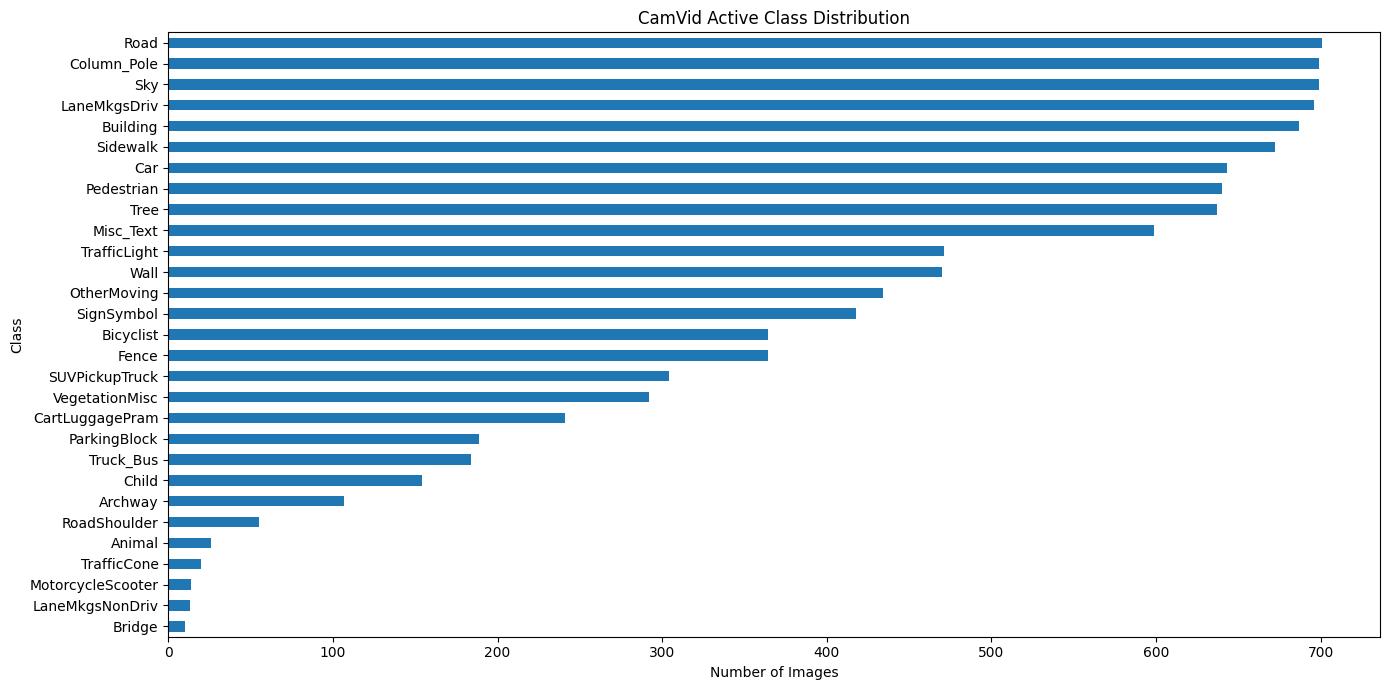

In [ ]:
plt.figure(figsize=(14, 7))

class_distribution.loc[ACTIVE_CLASSES, "Image Count"].sort_values().plot(
    kind="barh"
)

plt.title("CamVid Active Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

## 5. Create sequence identifiers

In [ ]:
df["sequence_id"] = (
    df["filename"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[0]
)

sequence_counts = df["sequence_id"].value_counts()

print("Number of sequences:", df["sequence_id"].nunique())
display(sequence_counts.rename("Image Count").to_frame())

Number of sequences: 4


,Image Count
sequence_id,
0016E5,305
Seq05VD,171
0001TP,124
0006R0,101


## 6. Split by sequence to avoid temporal leakage
For the current four sequences, the initial allocation is:
- Training: 0016E5, Seq05VD
- Validation: 0001TP
- Testing: 0006R0

This is a deterministic group split, not a random frame split.
It prevents frames from the same sequence from appearing in multiple subsets.

In [ ]:
TRAIN_SEQUENCES = ["0016E5", "0006R0"]
VAL_SEQUENCES = ["Seq05VD"]
TEST_SEQUENCES = ["0001TP"]

all_assigned_sequences = (
    TRAIN_SEQUENCES + VAL_SEQUENCES + TEST_SEQUENCES
)

assert len(all_assigned_sequences) == len(set(all_assigned_sequences))

assert set(all_assigned_sequences) == set(df["sequence_id"].unique())

df["split"] = np.select(
    [
        df["sequence_id"].isin(TRAIN_SEQUENCES),
        df["sequence_id"].isin(VAL_SEQUENCES),
        df["sequence_id"].isin(TEST_SEQUENCES)
    ],
    ["train", "validation", "test"],
    default="unassigned"
)

assert (df["split"] != "unassigned").all()

display(
    df.groupby("split").agg(
        Image_Count=("filename", "count"),
        Sequence_Count=("sequence_id", "nunique")
    )
)

,Image_Count,Sequence_Count
split,,
test,124,1
train,406,2
validation,171,1


## 7. Check class coverage in each split

In [ ]:
split_class_counts = (
    df.groupby("split")[ACTIVE_CLASSES]
    .sum()
    .T
)

display(split_class_counts)

coverage_rows = []

for split_name in ["train", "validation", "test"]:
    present_classes = (
        split_class_counts[split_name] > 0
    ).sum()

    coverage_rows.append({
        "Split": split_name,
        "Classes Present": int(present_classes),
        "Classes Missing": len(ACTIVE_CLASSES) - int(present_classes)
    })

display(pd.DataFrame(coverage_rows))

split,test,train,validation
Road,124,406,171
Sky,123,405,171
Column_Pole,123,405,171
LaneMkgsDriv,123,402,171
Building,124,395,168
Sidewalk,124,377,171
Car,124,358,161
Pedestrian,119,359,162
Tree,124,357,156
Misc_Text,102,354,143


,Split,Classes Present,Classes Missing
0,train,29,0
1,validation,26,3
2,test,22,7


In [ ]:
#Rare classes implementation, separate

rare_classes = class_counts[class_counts <= 30].index.tolist()

print("Rare classes (30 or fewer positive images):", rare_classes)

display(
    split_class_counts.loc[
        split_class_counts.index.intersection(rare_classes)
    ]
)

Rare classes (30 or fewer positive images): ['Animal', 'TrafficCone', 'MotorcycleScooter', 'LaneMkgsNonDriv', 'Bridge', 'Train', 'Tunnel']


split,test,train,validation
Animal,0,4,22
TrafficCone,0,17,3
MotorcycleScooter,0,14,0
LaneMkgsNonDriv,0,6,7
Bridge,0,10,0


## 8. Resolve image and mask paths

In [ ]:
def resolve_dataset_path(original_path, target_directory):
    filename = Path(str(original_path)).name
    return target_directory / filename


df["image_path"] = df["image"].apply(
    lambda p: resolve_dataset_path(p, IMAGE_DIR)
)

df["mask_path"] = df["mask"].apply(
    lambda p: resolve_dataset_path(p, MASK_DIR)
)

df["image_exists"] = df["image_path"].apply(
    lambda p: p.is_file()
)

df["mask_exists"] = df["mask_path"].apply(
    lambda p: p.is_file()
)

print("Images found:", df["image_exists"].sum(), "/", len(df))
print("Masks found:", df["mask_exists"].sum(), "/", len(df))

missing_images = df.loc[~df["image_exists"], "image_path"].tolist()
missing_masks = df.loc[~df["mask_exists"], "mask_path"].tolist()

print("\nMissing image examples:", missing_images[:5])
print("Missing mask examples:", missing_masks[:5])

Images found: 701 / 701
Masks found: 701 / 701

Missing image examples: []
Missing mask examples: []


## 9. Inspect image dimensions and channels

In [ ]:
image_properties = []

for image_path in df["image_path"]:
    with Image.open(image_path) as img:
        image_properties.append({
            "width": img.width,
            "height": img.height,
            "mode": img.mode
        })

image_properties_df = pd.DataFrame(image_properties)

print("Image dimensions:")
display(
    image_properties_df.groupby(
        ["width", "height", "mode"]
    ).size().rename("Count").to_frame()
)

Image dimensions:


,,,Count
width,height,mode,
960,720,RGB,701


## 10. Define preprocessing and augmentation
- The validation and test transformations are deterministic.
- Augmentation is applied only to training images.

In [ ]:
# Preserve the original 4:3 aspect ratio
# Resize to 224 x 168, then pad to 224 x 224.

train_transform = transforms.Compose([
    transforms.Resize((168, 224)),
    transforms.Pad(
        padding=(0, 28, 0, 28),
        fill=(124, 116, 104)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor()
])

evaluation_transform = transforms.Compose([
    transforms.Resize((168, 224)),
    transforms.Pad(
        padding=(0, 28, 0, 28),
        fill=(124, 116, 104)
    ),
    transforms.ToTensor()
])

## 11. Create the PyTorch Dataset

In [ ]:
class CamVidClassificationDataset(Dataset):

    def __init__(self, dataframe, class_columns, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.class_columns = class_columns
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        labels = torch.tensor(
            row[self.class_columns].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return {
            "image": image,
            "labels": labels,
            "filename": row["filename"]
        }

## 12. Build train, validation and test datasets

In [ ]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

train_dataset = CamVidClassificationDataset(
    train_df,
    ACTIVE_CLASSES,
    transform=train_transform
)

val_dataset = CamVidClassificationDataset(
    val_df,
    ACTIVE_CLASSES,
    transform=evaluation_transform
)

test_dataset = CamVidClassificationDataset(
    test_df,
    ACTIVE_CLASSES,
    transform=evaluation_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("Active target dimensions:", len(ACTIVE_CLASSES))

Training samples: 406
Validation samples: 171
Testing samples: 124
Active target dimensions: 29


## 13. Create DataLoaders

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 13
Validation batches: 6
Test batches: 4


## 14. Validate a sample batch

In [ ]:
batch = next(iter(train_loader))

images = batch["image"]
labels = batch["labels"]

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image value range:", images.min().item(), images.max().item())

assert images.ndim == 4
assert images.shape[1] == 3
assert labels.shape[1] == len(ACTIVE_CLASSES)
assert torch.isfinite(images).all()
assert torch.isfinite(labels).all()

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32, 29])
Image value range: 0.0 1.0


## 15. Visualize augmented training images and labels

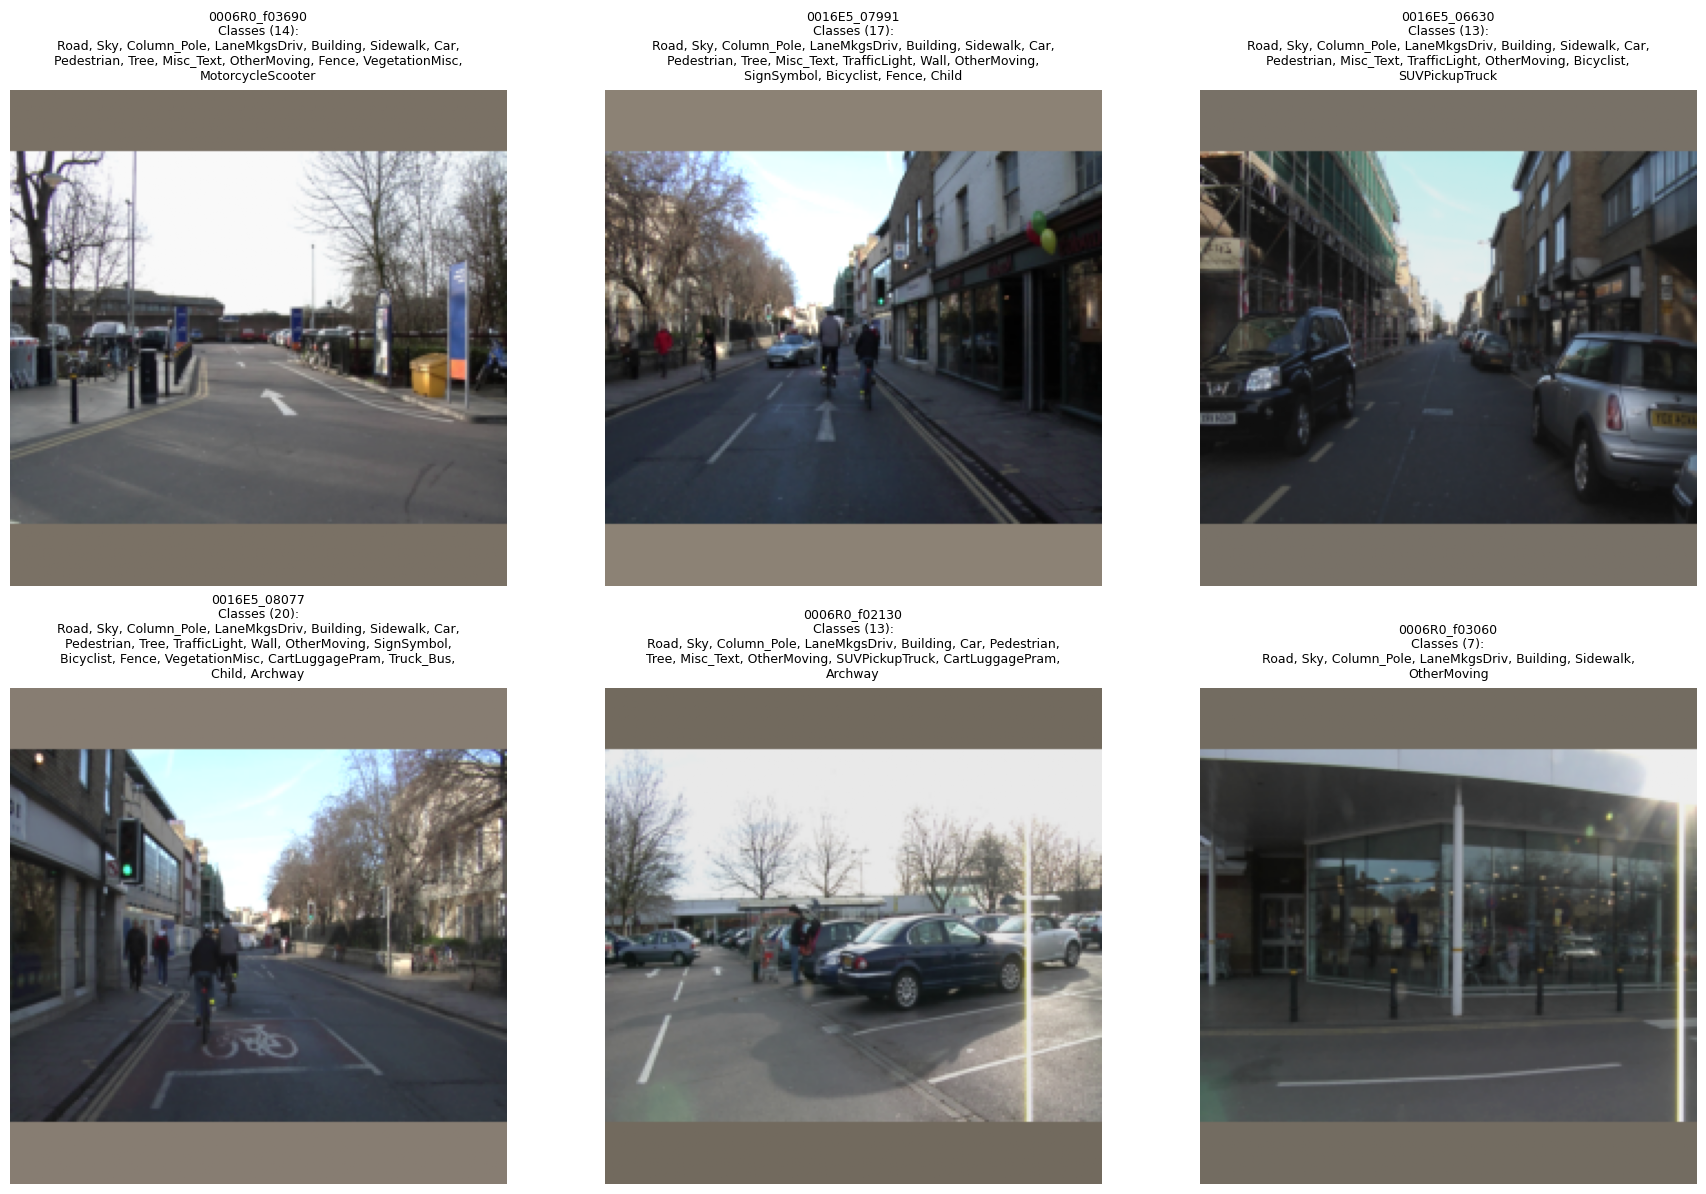

In [ ]:
import textwrap

def show_training_batch(batch, class_names, max_images=6):

    images = batch["image"]
    labels = batch["labels"]
    filenames = batch["filename"]

    count = min(max_images, len(images))

    fig, axes = plt.subplots(
        2, 3,
        figsize=(18, 12)
    )

    axes = axes.flatten()

    for i in range(count):

        image = images[i].permute(1, 2, 0).numpy()

        positive_labels = [
            class_names[j]
            for j, value in enumerate(labels[i])
            if value.item() == 1
        ]

        # Display every positive class
        label_text = ", ".join(positive_labels)

        # Wrap labels for readability
        label_text = textwrap.fill(
            label_text,
            width=65
        )

        axes[i].imshow(image)

        axes[i].set_title(
            f"{filenames[i]}\n"
            f"Classes ({len(positive_labels)}):\n"
            f"{label_text}",
            fontsize=9,
            pad=8
        )

        axes[i].axis("off")

    for i in range(count, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


show_training_batch(batch, ACTIVE_CLASSES)

## 16. Save preprocessing artifacts

In [ ]:
OUTPUT_DIR = DATASET_DIR / "preprocessed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the split assignments and resolved paths
df.to_csv(
    OUTPUT_DIR / "camvid_preprocessed_metadata.csv",
    index=False
)

# Save active class names and the original class list
pd.Series(ACTIVE_CLASSES, name="class_name").to_csv(
    OUTPUT_DIR / "active_classes.csv",
    index=False
)

pd.Series(CLASS_COLUMNS, name="class_name").to_csv(
    OUTPUT_DIR / "all_source_classes.csv",
    index=False
)

# Save split assignments separately
for split_name, split_df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    split_df.to_csv(
        OUTPUT_DIR / f"{split_name}_metadata.csv",
        index=False
    )

print("Preprocessing artifacts saved to:", OUTPUT_DIR)

Preprocessing artifacts saved to: /content/drive/MyDrive/AAI-521/project/datasets/camvid/preprocessed
